
## Module: Data Exploration & Preparation  
- ## **Lecturer:** Dr. Muhammad Iqbal  
- ## **Student Name/ID:** Agustin Villareal / sba26038  
- ## **Institution:** CCT College Dublin  
- ## **Submission Date:** Nov. 2026  
- ## **Dataset:** Smart Home Energy Telemetry (`Smart_Home_Energy.csv`)  


## Section 1 -EDA : Importing libraries
### Importing the Python libraries used in this project.

- **Pandas:** 
- **NumPy:** numeric calculations.
- **Matplotlib:** plots, with full control over the details.
- **Seaborn:** statistical plots, this project uses it, for example: for the correlation heatmap.

In [1]:
### Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


##  Section 1 -EDA: Loading the dataset
### Loading `Smart_Home_Energy.csv` - Display info of the Dataset
**The raw dataset `Smart_Home_Energy.csv` is loaded into a Pandas DataFrame. An initial inspection is performed to review data types.**
- **Info() to dsiplay the colums, type of and check null data**
- **file is named to storaged name of our CSV**
- **Dataset storaged in "smart_df"**


In [27]:
### Load the dataset, ### Load the dataset - Loading `Smart_Home_Energy.csv` into Dataframe `smart_df` and show the structure with info().
file = "Smart_Home_Energy.csv"
smart_df = pd.read_csv(file)
smart_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5507 entries, 0 to 5506
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   dwelling_type       5507 non-null   str    
 1   heating_type        5462 non-null   str    
 2   tariff_type         5416 non-null   str    
 3   occupants           5507 non-null   int64  
 4   floor_area_m2       5388 non-null   float64
 5   avg_outdoor_temp_c  5373 non-null   float64
 6   avg_daily_use_kwh   5450 non-null   float64
 7   monthly_bill_eur    5441 non-null   float64
dtypes: float64(4), int64(1), str(3)
memory usage: 467.0 KB


 ## Section 1-EDA - Initial inspection



- `head()` / `tail()`: 
- `describe()`:
- `describe(include="str")`: 
- `value_counts(dropna=False)`:
- `shape`

In [28]:
##### Statistical - Numerical colums
### Head of dataset - 0 to 4 
display(smart_df.head(5))

,dwelling_type,heating_type,tariff_type,occupants,floor_area_m2,avg_outdoor_temp_c,avg_daily_use_kwh,monthly_bill_eur
0,Semi-detached,Heat Pump,Standard,2,173.7,5.4,18.84,176.72
1,Detached,Gas,Smart,1,131.8,11.1,9.95,96.82
2,Semi-detached,Electric,Smart,4,146.5,12.6,19.54,239.75
3,Semi-detached,Oil,Smart,6,72.4,11.7,14.34,139.45
4,Semi-detached,Heat Pump,Smart,3,170.2,9.2,14.73,148.39


In [29]:
### Resuming and Displaying only cattegorys colums - they are 3 colums  - dwelling_type, heating_type, tariff_type.-  
###and 4 lines, display 4 measures. - counts , 
##Example dwelling_type, count 5507 field with data,unique: 4 diferent types, top:	Semi-detached is the most used,
## and appears qith a frecuency of 1626 times
display(smart_df.describe(include="str"))

,dwelling_type,heating_type,tariff_type
count,5507,5462,5416
unique,5,4,4
top,Semi-detached,Gas,Standard
freq,1626,2260,2473


In [5]:
## Tail displaying end of DataSet ending 5502 to 5506
display(smart_df.tail(5))



,dwelling_type,heating_type,tariff_type,occupants,floor_area_m2,avg_outdoor_temp_c,avg_daily_use_kwh,monthly_bill_eur
5502,Terraced,Gas,Night Saver,3,82.3,23.3,13.44,78.74
5503,Detached,Oil,Standard,6,127.7,14.2,17.13,122.18
5504,Apartment,Gas,Night Saver,5,48.9,17.6,12.71,135.49
5505,Terraced,Heat Pump,Standard,5,53.1,7.9,15.77,154.53
5506,Apartment,Oil,Night Saver,2,40.5,10.6,9.29,73.26


In [6]:
## describing and dsiplaying only numerical colums they are 5 numerical: 
### occupants, floor_area_m2, avg_outdoor_temp_c, avg_daily_use_kwh, monthly_bill_eur.
## rounded by 2 decimal for each data result
display(smart_df.describe().round(2))

,occupants,floor_area_m2,avg_outdoor_temp_c,avg_daily_use_kwh,monthly_bill_eur
count,5507.00,5388.00,5373.00,5450.00,5441.00
mean,3.62,126.09,10.29,19.39,196.92
std,1.86,78.36,5.43,16.43,190.92
min,1.00,30.30,-27.90,5.00,40.00
25%,2.00,86.80,7.10,13.49,122.60
50%,4.00,116.20,10.30,17.37,169.05
75%,5.00,151.70,13.50,21.28,228.82
max,20.00,946.70,46.00,219.42,2788.41


In [7]:
### function which is filterring only by these 3 data type
### ["object", "str", "category"]
categorical_columns = smart_df.select_dtypes(include=["object", "str", "category"]).columns


##### usig the function (categorical_columns) with a "for", 
######### turning with to_frame from series of plain text or data to Dataframe or table with a format.
# indluding NaN´s value or missing values in the loop  withe th drapna= "false".
######### This loop going iterate only the 3 categorical columns
# counting how many times, (for Example Semi-detached house in the catergory dwelling_type)
for column in categorical_columns:
   display(smart_df[column].value_counts(dropna=False).to_frame())

,count
dwelling_type,
Semi-detached,1626
Detached,1324
Terraced,1288
Apartment,1222
Semi Detached,47


,count
heating_type,
Gas,2260
Heat Pump,1577
Electric,838
Oil,787
NaN,45


,count
tariff_type,
Standard,2473
Smart,1897
Night Saver,1004
NaN,91
smart,42


In [8]:
print(smart_df.shape)      # Number of rows and columns
print(smart_df.shape[0])   # Number of rows
print(smart_df.shape[1])   # Number of columns

(5507, 8)
5507
8


In [9]:
# Calcualting of null values in the dataset
smart_df.isnull().sum()

dwelling_type           0
heating_type           45
tariff_type            91
occupants               0
floor_area_m2         119
avg_outdoor_temp_c    134
avg_daily_use_kwh      57
monthly_bill_eur       66
dtype: int64

In [10]:
# Checking the duplicate values

print("Duplicate values: ", smart_df.duplicated().sum())

Duplicate values:  157


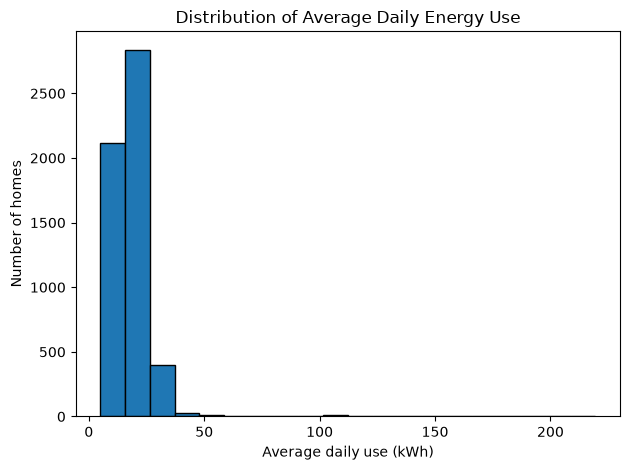

In [25]:
# Distribution of daily energy consumption
plt.hist(smart_df["avg_daily_use_kwh"], bins=20, edgecolor="black")
plt.title("Distribution of Average Daily Energy Use")
plt.xlabel("Average daily use (kWh)")
plt.ylabel("Number of homes")
plt.tight_layout()
plt.show()

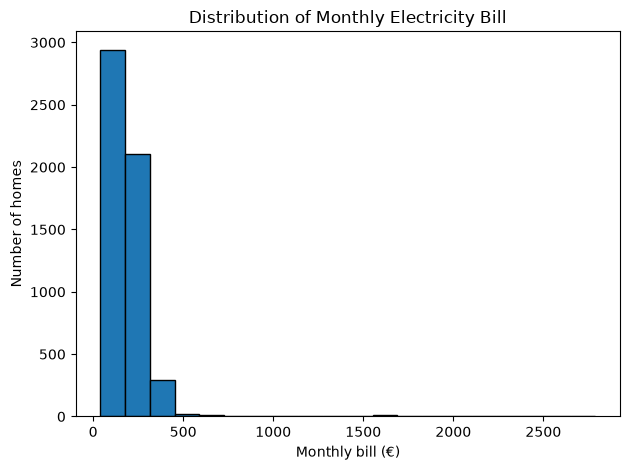

In [12]:
# Distribution of Monthly Electricity Bil
plt.hist(smart_df["monthly_bill_eur"], bins=20, edgecolor="black")
plt.title("Distribution of Monthly Electricity Bill")
plt.xlabel("Monthly bill (€)")
plt.ylabel("Number of homes")
plt.tight_layout()
plt.show()

## Section 2 Data Cleaning 

In [26]:
#### msssing count - counting NaN´s

missing_count = smart_df.isnull().sum()

missing_percentage = smart_df.isnull().mean() * 100

display(missing_count)


dwelling_type           0
heating_type           45
tariff_type            91
occupants               0
floor_area_m2         119
avg_outdoor_temp_c    134
avg_daily_use_kwh      57
monthly_bill_eur       66
dtype: int64

In [14]:
#### Porcentage of missing, not need to drop`any colum
missing_percentage = smart_df.isnull().mean() * 100
display(missing_percentage.round(2))


dwelling_type         0.00
heating_type          0.82
tariff_type           1.65
occupants             0.00
floor_area_m2         2.16
avg_outdoor_temp_c    2.43
avg_daily_use_kwh     1.04
monthly_bill_eur      1.20
dtype: float64

In [15]:
# Check the duplicate values -
duplicate_count = smart_df.duplicated().sum()
print("Duplicated found:", duplicate_count)

Duplicated found: 157


In [16]:
#### removing duplicates - Creating copy of original dataset
# Remove duplicated rows
df_analysis = smart_df.drop_duplicates().sum()
df_analysis = smart_df.drop_duplicates().copy()


print("Original number of rows:", len(smart_df))
print("After removing duplicated rows:", len(df_analysis))


Original number of rows: 5507
After removing duplicated rows: 5350


In [17]:
### Checking data types
print(smart_df.dtypes)

dwelling_type             str
heating_type              str
tariff_type               str
occupants               int64
floor_area_m2         float64
avg_outdoor_temp_c    float64
avg_daily_use_kwh     float64
monthly_bill_eur      float64
dtype: object


In [18]:
### Print Cattegories
numerical_columns = smart_df.select_dtypes(include = "number").columns.tolist()
categorical_columns = smart_df.select_dtypes(include = ["object","str", "category"]).columns.tolist()

print(numerical_columns)
print(categorical_columns)

['occupants', 'floor_area_m2', 'avg_outdoor_temp_c', 'avg_daily_use_kwh', 'monthly_bill_eur']
['dwelling_type', 'heating_type', 'tariff_type']


In [19]:
print(df_analysis[categorical_columns].isnull().sum())

dwelling_type     0
heating_type     45
tariff_type      90
dtype: int64


In [20]:
# Replace missing values in the categorical columns - Using the mode
categorical_columns = df_analysis.select_dtypes(include = ["object", "str", "category"]).columns

for column in categorical_columns:
    df_analysis[column] = df_analysis[column].fillna( df_analysis[column].mode()[0] )

print(df_analysis.isnull().sum())

dwelling_type           0
heating_type            0
tariff_type             0
occupants               0
floor_area_m2         115
avg_outdoor_temp_c    129
avg_daily_use_kwh      54
monthly_bill_eur       64
dtype: int64


In [21]:
print(df_analysis[numerical_columns].isnull().sum())

occupants               0
floor_area_m2         115
avg_outdoor_temp_c    129
avg_daily_use_kwh      54
monthly_bill_eur       64
dtype: int64


In [22]:
##  Replacing the numerical values Using the Mean
df_analysis['floor_area_m2'] = df_analysis['floor_area_m2'].fillna(df_analysis['floor_area_m2'].mean())
df_analysis['avg_outdoor_temp_c'] = df_analysis['avg_outdoor_temp_c'].fillna(df_analysis['avg_outdoor_temp_c'].mean())
df_analysis['avg_daily_use_kwh'] = df_analysis['avg_daily_use_kwh'].fillna(df_analysis['avg_daily_use_kwh'].mean())
df_analysis['monthly_bill_eur'] = df_analysis['monthly_bill_eur'].fillna(df_analysis['monthly_bill_eur'].mean())

# Check missing values
print(df_analysis.isnull().sum())

dwelling_type         0
heating_type          0
tariff_type           0
occupants             0
floor_area_m2         0
avg_outdoor_temp_c    0
avg_daily_use_kwh     0
monthly_bill_eur      0
dtype: int64


In [23]:
## checking shape of original Dataset
### Comparing with "df_analysis
print("Original dataset (smart_df):", smart_df.shape)
print("Cleaned dataset (df_analysis):", df_analysis.shape)

Original dataset (smart_df): (5507, 8)
Cleaned dataset (df_analysis): (5350, 8)


In [24]:
# Saving the new Cleaned dataset
df_analysis.to_csv("Smart_Home_Energy_cleaned.csv", index=False)